In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


In [ ]:
df = pd.read_csv("lizard_data.csv")
df.head()          # İlk 5 satır


,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
0,Uta,Disi,43.8,102.2,5.18,21.6,Yer
1,Sceloporus,Disi,62.1,149.8,16.78,29.7,Kaya
2,Uta,Disi,37.6,76.4,4.94,18.5,Yer
3,Sceloporus,Erkek,70.4,170.4,18.23,28.4,Yer
4,Anolis,Disi,52.7,137.9,8.60,25.8,Agac


In [ ]:
print('Satır sayısı:', df.shape[0])
print('Sütun sayısı:', df.shape[1])
print(df.columns.tolist())
df['YasamAlani'].value_counts()   # Her sınıftan kaç tane var?
df.describe().round(1)            # Sayısal özet


Satır sayısı: 320
Sütun sayısı: 7
['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu
count,320.0,320.0,320.0,320.0
mean,60.8,145.1,12.5,27.3
std,10.5,26.1,5.7,5.7
min,36.4,76.4,2.6,13.8
25%,52.7,124.4,8.2,22.8
50%,59.8,141.8,10.5,27.2
75%,69.6,166.2,17.4,31.0
max,83.3,209.4,25.9,43.9


In [ ]:
df['YasamAlani'].value_counts()   # Her sınıftan kaç tane var?


,count
YasamAlani,
Yer,151
Kaya,96
Agac,73


SORULAR VE CEVAPLARI

1-)Veri kümesinde kaç kertenkele var?

Veri kümesinde toplam 320 kertenkele vardır.

2-)Hangi yaşam alanı en kalabalık? Hangisi en az?

En kalabalık yaşam alanı "yer" en az olan ise "ağaç" dır.

3-)Bu dengesizlik modelimizi nasıl etkileyebilir? (Dersimizdeki “sınıf dengesi” tartışmasını hatırlayın.)

MCR oranını düşürmek için veri sayısı fazla olan sınıfı daha iyi öğrenmeye çalışırız.

4-)Kertenkelelerin ortalama ağırlığı nedir? Bu değer üç tür için farklı mıdır? Nedenini açıklayın.

Ağırlık ortalaması 12.5 dir. Bence her türün ağırlık ortalaması farklıdır çünkü
türlerin yaşam alanları ,özellikleri birbirinden farklılık göstermektedir.

In [ ]:
#3 soru seçme
1-)Bu kertenkelenin yaşam alanı ne olabilir?
2-)Bu kertenkelenin türü ne olabilir?
3-)Bu kertenkelenin cinsiyeti ne olabilir?

#ADIM 2

In [ ]:
#SORU 1-)Bu kertenkelenin yaşam alanı ne olabilir?

In [ ]:
hedef_degisken = 'YasamAlani'
ozellikler = [col for col in df.columns if col != hedef_degisken]
X = pd.get_dummies(df[ozellikler], drop_first=True)
y = df[hedef_degisken]
print("Modele girecek özellikler (X) sütunları:")
print(X.columns.tolist())

Modele girecek özellikler (X) sütunları:
['GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'Tur_Sceloporus', 'Tur_Uta', 'Cinsiyet_Erkek']


#ADIM 3

In [ ]:
derinlikler = [1, 2, 3, 4, 5]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")		# sütun başlıkları



  Derinlik   Eğitim MCR   Test MCR


In [ ]:
# Veriyi %80 Eğitim / %20 Test olarak bölüyoruz
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Eğitim seti boyutu:', len(X_egitim), 'kertenkele')
print('Test seti boyutu:', len(X_test), 'kertenkele')
print('\nEğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())

Eğitim seti boyutu: 256 kertenkele
Test seti boyutu: 64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64


In [ ]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
)

print('Eğitim seti boyutu:', len(X_egitim), 'kertenkele')
print('Test seti boyutu:', len(X_test), 'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())


Eğitim seti boyutu: 256 kertenkele
Test seti boyutu: 64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     123
Kaya     75
Agac     58
Name: count, dtype: int64


stratify=y parametresini kaldırdığım zaman bana yaşam alanları orantılı bir şeklide dağıtmıyor. Buda mesela ağaçda yaşayan kertenkelelerin hepsinin test verisine gitmesine neden olabilir. yaptığım örnekte çok fark olmasada karar ağacımı hazırlarken önemli değişikliklere sebep olabilir.

In [ ]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Eğitim seti boyutu:', len(X_egitim), 'kertenkele')
print('Test seti boyutu:', len(X_test), 'kertenkele')
print('\nEğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())

Eğitim seti boyutu: 256 kertenkele
Test seti boyutu: 64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64


In [ ]:
erinlikler = [1, 2, 3, 4, 5]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")



  Derinlik   Eğitim MCR   Test MCR
         1        0.488      0.484
         2        0.359      0.312
         3        0.352      0.328
         4        0.324      0.328
         5        0.285      0.438


In [ ]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=7,
    stratify=y
)

print('Eğitim seti boyutu:', len(X_egitim), 'kertenkele')
print('Test seti boyutu:', len(X_test), 'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())


Eğitim seti boyutu: 256 kertenkele
Test seti boyutu: 64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64


In [ ]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")


         1        0.484      0.500
         2        0.355      0.328
         3        0.352      0.328
         4        0.312      0.391
         5        0.289      0.391


random state değerini 7 ve 42 aldığımda mcr değerlerimde değişiklikler meydana geliyor bunun nedeni ise random state veriyi her seferinde aynı yerden bölmemizi sağlar bunu başka sayıda alabiliriz ama her zaman aynı sayıyı kullanmamız gerekir bu sabit bir değişkendir.

In [ ]:
# Veriyi %80 Eğitim / %20 Test olarak bölüyoruz
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Eğitim seti boyutu:', len(X_egitim), 'kertenkele')
print('Test seti boyutu:', len(X_test), 'kertenkele')
print('\nEğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())

Eğitim seti boyutu: 256 kertenkele
Test seti boyutu: 64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64


#ADIM 4

In [ ]:
derinlikler = [1, 2, 3, 4, 5,]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")		# sütun başlıkları

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")



  Derinlik   Eğitim MCR   Test MCR
         1        0.488      0.484
         2        0.359      0.312
         3        0.352      0.328
         4        0.324      0.328
         5        0.285      0.438


SORULAR VE CEVAPLARI

1-)Çıktıya bakarak eğitim ve test hatasının derinlik arttıkça nasıl değişmektedir? Eğitim ve test değerlerine bakarak gerekçenizi yazın.


Derinlik arttıkça Eğitim MCR sürekli ve düzenli bir şekilde düşmektedir. Model, eğitim setindeki kertenkeleleri her adımda daha detaylı öğrenmektedir. Ancak Test MCR için aynı şeyi söyleyemeyiz. Derinlik 1'den 2'ye geçerken test hatası düşmüş ve en başarı noktasını görmüştür; fakat derinlik 5'e ulaştığında test hatası ani ve çok büyük bir sıçrama yaparak 0.438'e yükselmiştir.

2-)Eğitim hatası sıfıra yaklaşıyorsa bu modelin "mükemmel" öğrendiği anlamına gelir mi? Sizce ne anlama geliyor?


Hayır mükemmel öğrendiği anlamına gelmez bu durum modelin öğrenmeyi bırakıp ezbere geçtiği anlamına gelir bizim için önemli olan test verisindeki başarısıdır.

3-)Hangi derinlikte eğitim hatası düşmeye devam ederken test hatası artmaya başladı? O satırda modele ne olduğunu açıklayın.

Derinlik 5 te eğitim MCR si düşerken test MCR si yükselmiştir. Bu da overfitting durumudur.

4-)Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz? Hem eğitim hem test hatasını göz önünde bulundurarak gerekçenizi yazın.

2 yi seçerdim çünkü benim için önemli olan test verisidir.

5-)En düşük test hatası (MCR) ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu size ne söylüyor?


Evet, farklı derinliklerde çıkmıştır. En düşük test hatası Derinlik 2'de çıkarken, en düşük eğitim hatası Derinlik 5'te çıkmıştır. Bu durum bize karar ağaçlarının derinliği sınırlandırılmadığında sadece eğitim verisine odaklandığını söyler. Ayrıca makine öğrenmesinde model başarısını doğrulamak için neden veriyi "Eğitim" ve "Test" olarak ikiye ayırmamız gerektiğinin gerekçesidir.


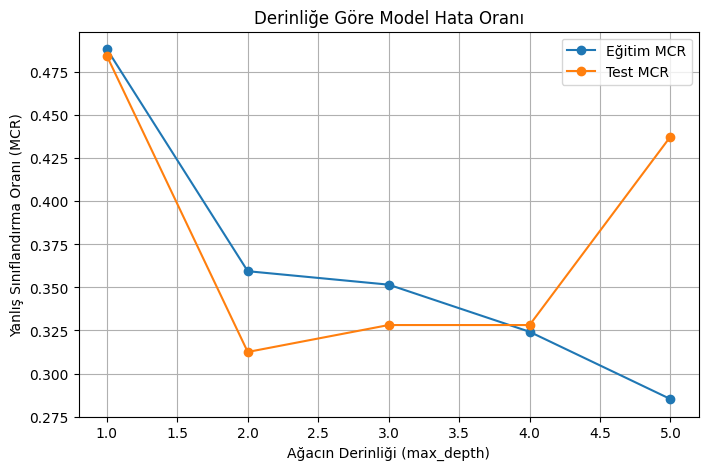

In [ ]:
egitim_mcr = []
test_mcr = []

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()


SORULAR VE CEVAPLARI

1-)Grafikteki iki eğri birbirinden ne zaman ayrılmaya başlıyor? Bu ayrılma noktası size ne söylüyor?

Derinlik 2'den sonra birbirinden ayrılmaya başlıyor. Derinlik 2'de test hatası dip noktayı görmüşken, derinlik arttıkça mavi eğri aşağı doğru inmeye devam ediyor, ancak turuncu eğri yönünü yukarı çeviriyor.

2-)Eğitim ve test eğrileri arasındaki mesafe derinlikle birlikte açılıyorsa buna ne ad verilir?

Bu duruma makine öğrenmesinde Aşırı Öğrenme (Overfitting) denir

3-)Grafiğe bakarak hangi max_depth değerini seçerdiniz? Sayısal tablodaki kararınızla aynı mı?

Evet, sayısal tablodaki kararımla aynıdır. Çünkü turuncu çizginin en dipte yer aldığı, yani modelin en az hata yaptığı ve en yüksek başarıyı gösterdiği noktası tam olarak Derinlik 2 seviyesidir.

4-)Kurduğunuz her karar ağacı için bu grafiği ayrı ayrı çizin. Optimum derinlik her hedef için aynı mı çıktı? Farklılaştıysa neden?

Hayır, her hedef değişken için optimum derinlik seviyeleri farklılık göstermiştir.Çünkü kertenkelelerin özellikleriyle sorduğumuz sorular arasındaki ilişki farklıdır. Örneğin, kertenkelenin Türünü tahmin etmek fiziksel ölçümlerle çok daha kolay ve netken, Cinsiyetini veya yaşam alanını bulmak daha karmaşık kurallar gerektirir. Bu yüzden her sorunun en başarılı olduğu derinlik seviyesi verinin kendi doğasına göre değişir.(diğer karar ağaçlarına baktıktan sonra cevapladım)






#ADIM 5

In [ ]:
optimum_derinlik =2  # Grafiğe bakarak siz belirleyin
final_agac =DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)

# Test verisinin MCR’si
y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatası (MCR): {test_mcr:.4f}')




Optimum Derinlik: 2
Test Hatası (MCR): 0.3125


In [ ]:
# Test verisinin MCR’si
y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatası (MCR): {test_mcr:.4f}')

Optimum Derinlik: 2
Test Hatası (MCR): 0.3125


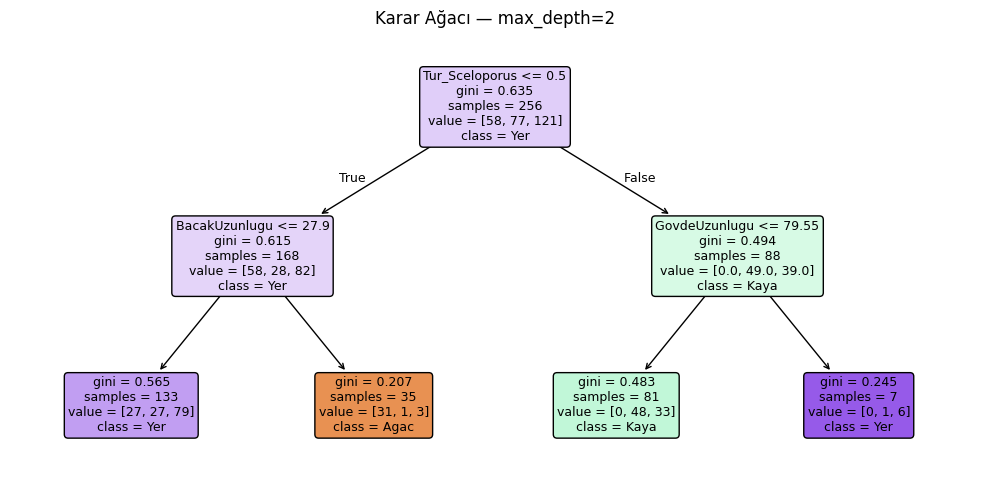

In [ ]:
plt.figure(figsize=(10, 5))
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac.classes_.astype(str)),      # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f'Karar Ağacı — max_depth={optimum_derinlik}')
plt.tight_layout()
plt.show()


SORU VE CEVAPLAR

1-)Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz?

Ürettiğim şemada kök düğümde Tur_Sceloporus değişkeni kullanılmıştır.Bu değişkenin ilk sırada yer alması, kertenkelelerin yaşam alanlarını tahmin etmede en ayırt edici kriterinin kertenkelenin Sceloporus türüne ait olup olmaması olduğunu gösterir.

2-)Ağaç yapraktan köke doğru okunduğunda bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?

Herhangi bir kertenkeleyi sınıflandırmak için en fazla 2 karar yeterli olmaktadır.Bu durum, modelin karmaşık kurallardan arınmış,sade, anlaşılır ve genelleme yeteneği yüksek bir yapıya sahip olduğunu söyler.

3-)Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız?

Evet, kök düğümler tamamen değişmiştir. Çünkü her ağaç en bilgi verici ve en ayırt edici özelliği kullanmıştır.

#DİĞER AĞAÇLAR

Derinlik   Eğitim MCR   Test MCR  
-----------------------------------
1          0.266        0.281     
2          0.191        0.219     
3          0.184        0.203     
4          0.137        0.281     
5          0.102        0.203     
6          0.078        0.250     
7          0.031        0.219     
8          0.020        0.234     
9          0.000        0.250     
10         0.000        0.250     


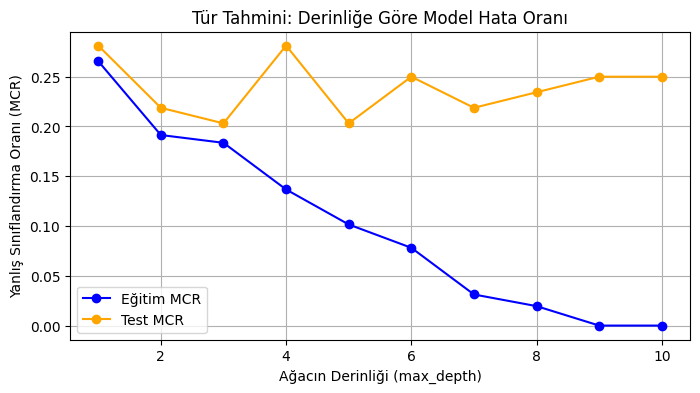

In [ ]:
hedef_degisken_2 = 'Tur'
ozellikler_2 = [col for col in df.columns if col != hedef_degisken_2]


X_2 = pd.get_dummies(df[ozellikler_2], drop_first=True)
y_2 = df[hedef_degisken_2]


X_egitim_2, X_test_2, y_egitim_2, y_test_2 = train_test_split(
    X_2, y_2, test_size=0.2, random_state=42, stratify=y_2
)

derinlikler = list(range(1, 11))
egitim_mcr_2 = []
test_mcr_2 = []

print(f"{'Derinlik':<10} {'Eğitim MCR':<12} {'Test MCR':<10}")
print("-" * 35)

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim_2, y_egitim_2)

    e_mcr = 1 - accuracy_score(y_egitim_2, agac.predict(X_egitim_2))
    t_mcr = 1 - accuracy_score(y_test_2, agac.predict(X_test_2))

    egitim_mcr_2.append(e_mcr)
    test_mcr_2.append(t_mcr)
    print(f"{derinlik:<10} {e_mcr:<12.3f} {t_mcr:<10.3f}")


plt.figure(figsize=(8, 4))
plt.plot(derinlikler, egitim_mcr_2, marker='o', label='Eğitim MCR', color='blue')
plt.plot(derinlikler, test_mcr_2, marker='o', label='Test MCR', color='orange')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Tür Tahmini: Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()

Tür Tahmini Final Test Hatası (MCR): 0.2031


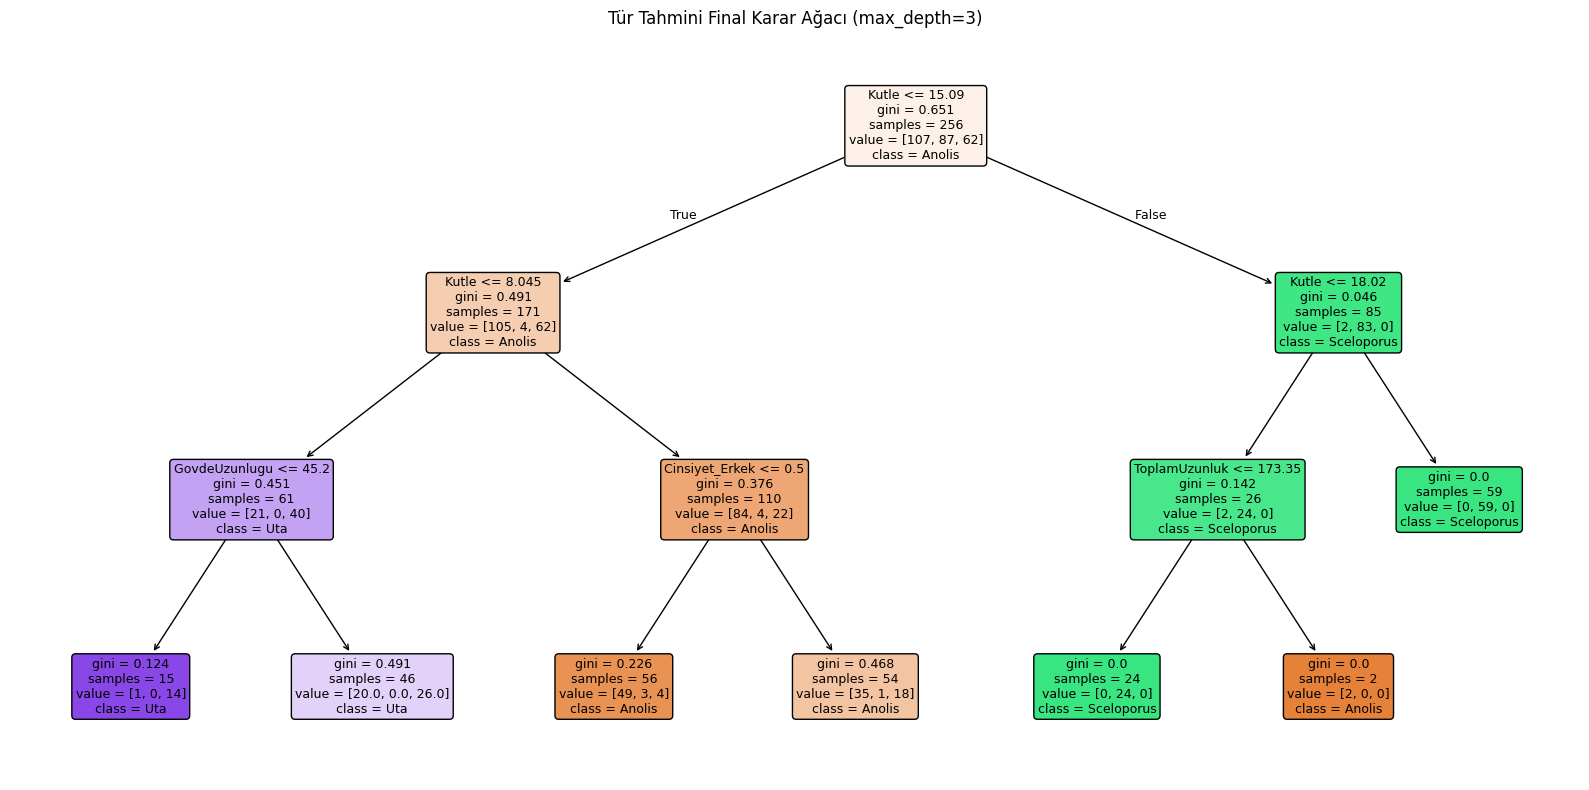

In [ ]:
optimum_derinlik_2 = 3

final_agac_2 = DecisionTreeClassifier(max_depth=optimum_derinlik_2, random_state=42)
final_agac_2.fit(X_egitim_2, y_egitim_2)

print(f"Tür Tahmini Final Test Hatası (MCR): {1 - accuracy_score(y_test_2, final_agac_2.predict(X_test_2)):.4f}")

plt.figure(figsize=(16, 8))
plot_tree(
    final_agac_2,
    feature_names=X_2.columns.tolist(),
    class_names=list(final_agac_2.classes_.astype(str)),
    filled=True, rounded=True, fontsize=9
)
plt.title(f'Tür Tahmini Final Karar Ağacı (max_depth={optimum_derinlik_2})')
plt.tight_layout()
plt.show()

Derinlik   Eğitim MCR   Test MCR  
-----------------------------------
1          0.352        0.438     
2          0.344        0.438     
3          0.223        0.328     
4          0.215        0.328     
5          0.156        0.312     
6          0.152        0.312     
7          0.102        0.375     
8          0.051        0.297     
9          0.020        0.328     
10         0.012        0.359     


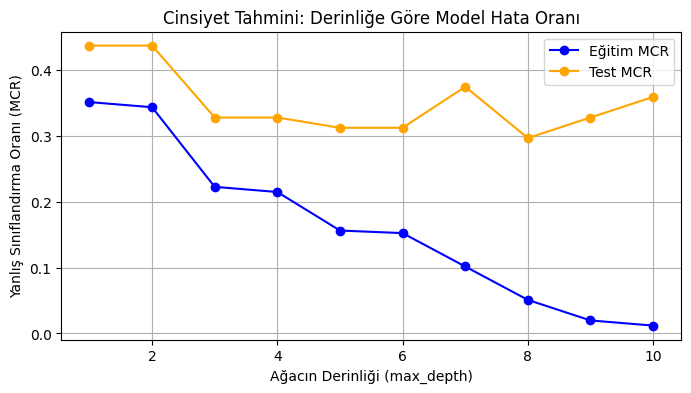

In [ ]:

hedef_degisken_3 = 'Cinsiyet'
ozellikler_3 = [col for col in df.columns if col != hedef_degisken_3]


X_3 = pd.get_dummies(df[ozellikler_3], drop_first=True)
y_3 = df[hedef_degisken_3]


X_egitim_3, X_test_3, y_egitim_3, y_test_3 = train_test_split(
    X_3, y_3, test_size=0.2, random_state=42, stratify=y_3
)

egitim_mcr_3 = []
test_mcr_3 = []

print(f"{'Derinlik':<10} {'Eğitim MCR':<12} {'Test MCR':<10}")
print("-" * 35)

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim_3, y_egitim_3)

    e_mcr = 1 - accuracy_score(y_egitim_3, agac.predict(X_egitim_3))
    t_mcr = 1 - accuracy_score(y_test_3, agac.predict(X_test_3))

    egitim_mcr_3.append(e_mcr)
    test_mcr_3.append(t_mcr)
    print(f"{derinlik:<10} {e_mcr:<12.3f} {t_mcr:<10.3f}")


plt.figure(figsize=(8, 4))
plt.plot(derinlikler, egitim_mcr_3, marker='o', label='Eğitim MCR', color='blue')
plt.plot(derinlikler, test_mcr_3, marker='o', label='Test MCR', color='orange')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Cinsiyet Tahmini: Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()

Cinsiyet Tahmini Final Test Hatası (MCR): 0.4375


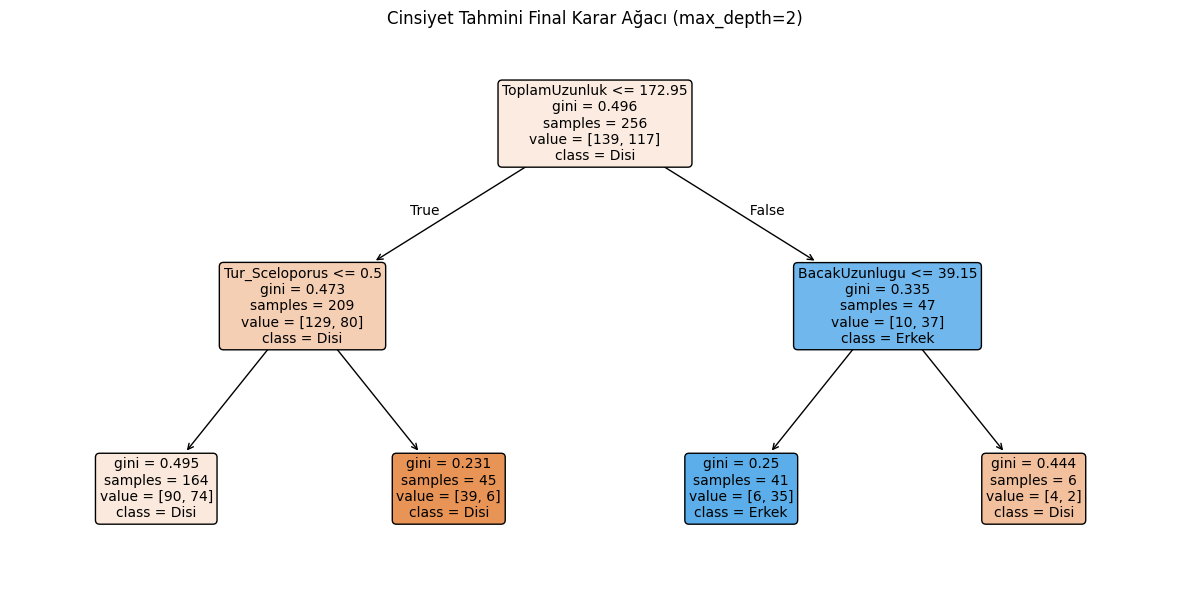

In [ ]:
optimum_derinlik_3 = 2

final_agac_3 = DecisionTreeClassifier(max_depth=optimum_derinlik_3, random_state=42)
final_agac_3.fit(X_egitim_3, y_egitim_3)

print(f"Cinsiyet Tahmini Final Test Hatası (MCR): {1 - accuracy_score(y_test_3, final_agac_3.predict(X_test_3)):.4f}")

plt.figure(figsize=(12, 6))
plot_tree(
    final_agac_3,
    feature_names=X_3.columns.tolist(),
    class_names=list(final_agac_3.classes_.astype(str)),
    filled=True, rounded=True, fontsize=10
)
plt.title(f'Cinsiyet Tahmini Final Karar Ağacı (max_depth={optimum_derinlik_3})')
plt.tight_layout()
plt.show()

#ADIM 6

#Soru 1 — Öğrenme Yolculuğu


Her ortam size farklı bir şey kattı mı? Her bir ortamın neler kattığını yazın.

- Evet her ortam düşünme becerime farklı bir boyut kalktı. Data kartları karar ağaçlarının arkasındaki mantığı, verileri fiziksel olarak gruplamayı ve bölünme kriterlerini somut olarak anlamamı sağladı. CODAP ise büyük veri setlerinde değişkenler arasındaki ilişkileri  görmemi ve model kurma deneyimi edinmemi sağladı.Python ise işin içine matematik sokarak, büyük ölçekli verilerde insan hatasından arınmış, tamamen istatistiksel ve bilimsel modeller kurma gücü kattı.

Hangi ortamda "modelim ne yapıyor" sorusunu daha iyi anladınız? Nedeninizi açıklayın.

- CODAP ortamında daha iyi anladım. Çünkü yaptığım her hamlede verinin grafik üzerinde nasıl değiştiğini inceleyebildik

Hangi ortam size daha kolay geldi? Bu kolaylık gerçekten anladığınızı mı, yoksa sadece alıştığınızı mı gösteriyor? Nedeninizi açıklayın.

- Kullanım kolaylığı açısından CODAP ortamı en kolayıydı çünkü kod yazma baskısı veya kod hatası alma korkusu olmadan sadece veriye odaklanabiliyordum ama bu kolaylık konuyu tamamen anladığımı değil, aracın arayüzüne hızlıca alıştığımı gösteriyordu.

Hangi ortamda en çok zorlandınız ve bu zorluk neden kaynaklanıyordu? Aracın kendisi mi, yoksa karar ağacı kavramının o ortamda daha mı görünmez olması mıydı? Nedeninizi açıklayın.

- En çok Python ortamında zorlandım. Bu zorluk karar ağacı kavramının görünmez olmasından değil, tamamen aracın kendisinden kaynaklanıyordu. Çünkü kodlama,  kütüphane entegrasyonları, ağaç çizimi için yazdığım kodlar bunlar karmaşık ve alışılması zordu.

Yaptığınız bir hatayı hangi ortamda daha kolay fark ettiniz? Sizi uyaran şey aracın kendisi miydi, yoksa başka bir şey mi?

- Python ortamında fark ettim. Çünkü Python bir hata yapıldığında kodun hangi satırda durduğunu ve hatanın ne olduğunu söylüyordu.

Bir ortamda rahatlıkla yapabildiğiniz ama bir diğerinde hiç yapamadığınız bir şey oldu mu?

- Python'daki for döngüsü olabilir.

Üç ortamdan birinin diğerinin yerini tutamayacağı bir durum var mı? Nedeninizi açıklayın.

- Bence data kartları çünkü somut nesnelerle öğrenmek çok daha kolay ve eğlenceliydi.


#Soru 2 — Veri Anlayışı

Modelinizin kök düğümde seçtiği değişken sizi şaşırttı mı? Biyolojik açıdan bu seçim mantıklı mı?

- Yasam alanı tahmininde modelin kök düğüm olarak tür değişkenini seçmesi başlangıçta şaşırttı çünkü ben ilk olarak fiziksel bir ölçüm bekliyordum. Ancak biyolojik açıdan düşününce bu seçim kesinlikle çok mantıklıymış.


Ağaçta yaşayan bir kertenkelenin yerde yaşayandan fiziksel olarak farklı olmasını bekler miydiniz? Modeliniz bu farkı yakalayabildi mi?

- Beklerdim çünkü ağaçta yaşayan kertenkelelerin dallara tutunabilmesi ve tırmanış yapabilmek için bacak boylarının ve kütlelerinin yerde yaşayanlara göre daha farklı olması gerekir. Ağacda da zaten dalların birinde bacak uzunluğuna göre ağaç yaşam alanı sınıfına yerleştiriyor.

Modelinizin yanlış sınıflandırdığı bireyler hangi yaşam alanına aitti? Bunun biyolojik bir açıklaması olabilir mi?

- Genellikle yer ve kaya türlerinde çünkü yaşam alanları birbirine benzer olduğundan dolayı biyolojik olarak da biribirine benziyorlar.

Veriyi ilk gördüğünüzde kendiniz hangi değişkenin en belirleyici olacağını tahmin etmiştiniz? Modelinizin bulgusuyla örtüştü mü?

- Kütle diye tahmin etmiştim ama modelim yaşam alanı seçti uyuşmadı ama sonradan düşününce yaşam alanı daha mantıklıymış.

#Soru 3 — Model Performansı

Hangi sınıf en iyi, hangisi en kötü tahmin edildi? Bunun bir açıklaması var mı?

- En iyi tahmin edilen sınıf Kaya ve Ağaç olurken, en kötü tahmin edilen  sınıf Yer sınıfı olmuştur. Bunun açıklaması sınıf dengesizliği ve morfolojik benzerlik olabilir.

MCR değeriniz sizi tatmin etti mi? "İyi" bir model için bu değerin ne olması gerektiğini düşünüyorsunuz?

- Bulduğum değer güzzel ama daha hatasız ve daha iyi sonuç elde edebilecek bir karar ağacı yapmak istiyorsam bunu daha da düşürmem gereklidir.

Aynı veriyle farklı bir hedef değişken seçseydiniz (Tur ya da Cinsiyet) MCR değeri değişir miydi? Değiştiyse neden?

- Evet değişti ve kodlarımızda da bunu gördük. Örneğin hedef değişkeni Tur yaptığımızda test MCR değeri çok daha düşük çıktı çünkü kertenkelelerin tür özellikleri veride çok daha keskin sınırlara sahipti.

Modelin başarısız olduğu durumlar size veri hakkında ne söylüyor?

- Modelin başarısız olduğu durumlar bize, kertenkeleleri sadece fiziksel ölçümlerine bakarak yaşam alanlarına ayırmanın yetersiz kalabileceğini söylüyor.

#Soru 4 — Karar Ağaçlarının Sınırları

Modelinizin hata yaptığı durumlar rastgele mi görünüyor, yoksa belirli bir örüntü var mı?

-Hatalar rastgele değildir belirli bir matematiksel örüntüye sahiptir.

Bu modelin daha iyi sonuç verebilmesi için neler yapılabilir? Yalnızca teknik değil, verinin kendisiyle ilgili ne değişebilir?

-Veri setine biyolojik özellikler eklenebilir mesela beslenme türü veya yaşadıkları bölgenin iklimi gibi sadece fiziksel özelliklerden çıkarak daha geniş bir açıdan bakabiliriz.

Karar ağacı yerine farklı bir model kullansaydınız sonuç değişir miydi? Neden?

- Karar ağacından başka modele bakmam.

Bu deneyimden sonra bir arkadaşınıza "karar ağacı nedir, ne işe yarar, nerede yetersiz kalır?" diye sorsalar ne söylerdiniz?

-Karar ağacı verileri anlamlandırmaya, gruplandırmaya, en önemli değişkenleri keşfetmeye ve anlaşılır kurallar üretmeye yarar. Ancak veriyi öğrenmek yerine ezberlemeye geçerse yani overfitting yapmaya başlarsa işe yaramaz.

